# MST-Based Clustering for Non-Linearly Separable Patterns
Conventional partitioning algorithms like $k$-means rely on Euclidean distances to cluster centroids, which imposes Voronoi tessellations and assumes convex, isotropic (spherical) cluster geometries. On non-linearly separable manifolds—such as interlocking moons, concentric rings, or spirals—centroid-based partitioning fails by slicing across natural density-connected boundaries. Minimum Spanning Tree (MST) clustering overcomes this limitation by modeling the dataset as a complete weighted graph, extracting the minimal-weight acyclic skeleton that preserves local connectivity, and removing inconsistent or globally longest edges to recover arbitrary cluster shapes.

## 1. Environment Setup and Reproducibility
This cell imports the standard scientific stack pre-installed in Google Colab (`numpy`, `scipy`, `scikit-learn`, `pandas`, `matplotlib`, and `seaborn`). A global random seed (`SEED = 42`) is initialized across `numpy` and `scikit-learn` routines to guarantee deterministic dataset synthesis and clustering outputs during your viva demonstration.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial.distance import cdist
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from scipy.sparse import csr_matrix

from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.metrics.cluster import contingency_matrix

warnings.filterwarnings('ignore')

# Set global random seed for complete reproducibility
SEED = 42
np.random.seed(SEED)

# Configure plotting style for clear presentation
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
sns.set_palette("tab10")
print("Environment initialized successfully with SEED =", SEED)

Environment initialized successfully with SEED = 42


## 2. Synthetic Dataset Generation
We construct a modular generator for four canonical topologies: **Two Moons**, **Concentric Circles**, **Two Intertwined Spirals** (custom parametric equations $r = a + b\theta$ with additive Gaussian perturbations), and **Anisotropic Blobs** (sheared via a linear transformation matrix as a control). Every dataset is standardized to zero mean and unit variance so edge weights remain comparable across geometries.

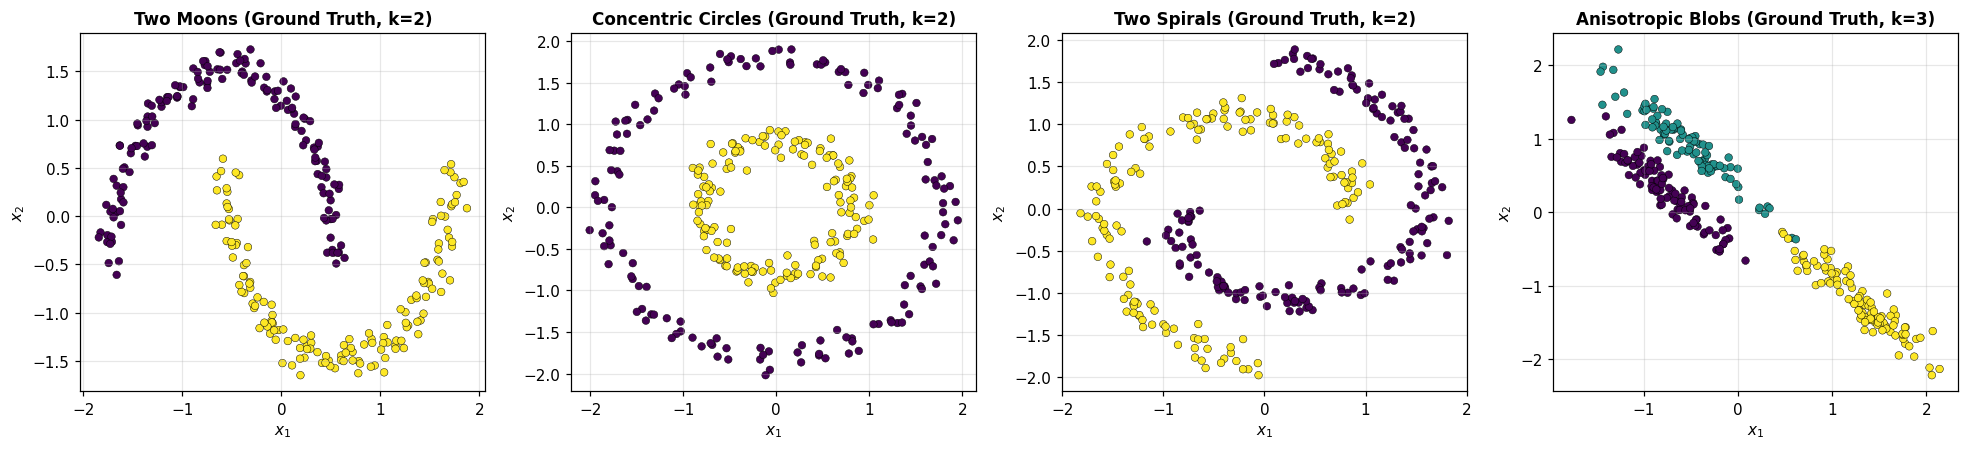

In [2]:
def make_spirals(n_samples=300, noise=0.04, random_state=SEED):
    """
    Generates two intertwined Archimedean spirals in 2D space.
    Viva note: Points are sampled along angle theta in [0.5*pi, 3.2*pi]
    so the inner tips remain separated while the arms wrap around each other.
    """
    rng = np.random.RandomState(random_state)
    n_per_arm = n_samples // 2

    # Square root sampling ensures roughly uniform arc-length spacing along the spiral
    theta = np.sqrt(rng.uniform(0.15, 1.0, n_per_arm)) * 2.5 * np.pi
    r = theta

    # Arm 1: (r*cos(theta), r*sin(theta))
    x1 = r * np.cos(theta) + rng.normal(0, noise * 8.0, n_per_arm)
    y1 = r * np.sin(theta) + rng.normal(0, noise * 8.0, n_per_arm)

    # Arm 2: rotated by pi radians (-r*cos(theta), -r*sin(theta))
    x2 = -r * np.cos(theta) + rng.normal(0, noise * 8.0, n_per_arm)
    y2 = -r * np.sin(theta) + rng.normal(0, noise * 8.0, n_per_arm)

    X = np.vstack([np.column_stack([x1, y1]), np.column_stack([x2, y2])])
    y = np.hstack([np.zeros(n_per_arm, dtype=int), np.ones(n_per_arm, dtype=int)])
    return X, y

def generate_all_datasets(n_samples=300, noise=0.05, random_state=SEED):
    """
    Generates and standardizes the 4 benchmark datasets along with ground-truth k.
    """
    # 1. Two Moons (k = 2)
    X_moons, y_moons = make_moons(n_samples=n_samples, noise=noise, random_state=random_state)

    # 2. Concentric Circles (k = 2, factor=0.45 keeps clear radial gap)
    X_circles, y_circles = make_circles(n_samples=n_samples, factor=0.45, noise=noise, random_state=random_state)

    # 3. Intertwined Spirals (k = 2)
    X_spirals, y_spirals = make_spirals(n_samples=n_samples, noise=noise, random_state=random_state)

    # 4. Anisotropic Blobs (Control dataset, k = 3)
    X_raw_blobs, y_blobs = make_blobs(
        n_samples=n_samples, centers=[[-3, -2], [0, 2], [3, -1]],
        cluster_std=0.6 + 6.0 * noise, random_state=random_state
    )
    # Apply linear shear transformation to stretch spherical blobs into elongated ellipses
    transformation = np.array([[0.6, -0.6], [-0.4, 0.8]])
    X_aniso = np.dot(X_raw_blobs, transformation)

    datasets = {
        "Two Moons": (StandardScaler().fit_transform(X_moons), y_moons, 2),
        "Concentric Circles": (StandardScaler().fit_transform(X_circles), y_circles, 2),
        "Two Spirals": (StandardScaler().fit_transform(X_spirals), y_spirals, 2),
        "Anisotropic Blobs": (StandardScaler().fit_transform(X_aniso), y_blobs, 3)
    }
    return datasets

# Generate datasets and plot ground truth
datasets = generate_all_datasets(n_samples=300, noise=0.05, random_state=SEED)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, (X, y, k)) in zip(axes, datasets.items()):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=25, edgecolor='k', linewidth=0.3)
    ax.set_title(f"{name} (Ground Truth, k={k})", fontsize=11, fontweight='bold')
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

## 3. MST Construction from Scratch (Prim's Algorithm) and Verification
Here we compute the full pairwise Euclidean distance matrix $D \in \mathbb{R}^{n \times n}$ and implement Prim's greedy MST algorithm in $O(n^2)$ time using an array of minimum attachment weights (`min_edge_weight`). We then cross-check our custom implementation's total spanning tree weight against `scipy.sparse.csgraph.minimum_spanning_tree` to verify exact mathematical equivalence.

In [3]:
def compute_distance_matrix(X):
    """Computes the pairwise Euclidean distance matrix D where D[i, j] = ||x_i - x_j||_2."""
    return cdist(X, X, metric='euclidean')

def prims_mst_from_scratch(D):
    """
    Dense O(n^2) implementation of Prim's Algorithm for complete graphs.
    Viva explanation:
      - We maintain three arrays of size n:
        1) in_mst: boolean flag tracking visited vertices.
        2) key: minimum weight of any edge connecting vertex v to the growing tree.
        3) parent: tree node that achieves key[v].
      - At each of n iterations, we pick the unvisited vertex u with minimum key[u],
        mark it visited, and relax all unvisited neighbors v using D[u, v].
    Returns:
      edges: numpy array of shape (n-1, 3) where each row is [u, v, weight]
      total_weight: sum of all n-1 MST edge weights
    """
    n = D.shape[0]
    in_mst = np.zeros(n, dtype=bool)
    key = np.full(n, np.inf)
    parent = np.full(n, -1, dtype=int)

    # Start Prim's traversal from vertex 0
    key[0] = 0.0
    edges = []

    for _ in range(n):
        # Find unvisited vertex u with the smallest key value
        masked_keys = np.where(in_mst, np.inf, key)
        u = int(np.argmin(masked_keys))
        in_mst[u] = True

        # Record the tree edge if u is not the root node
        if parent[u] != -1:
            edges.append((parent[u], u, key[u]))

        # Relax edges from u to all remaining unvisited vertices v
        unvisited_mask = ~in_mst
        better_edge_mask = unvisited_mask & (D[u] < key)
        parent[better_edge_mask] = u
        key[better_edge_mask] = D[u, better_edge_mask]

    edges = np.array(edges, dtype=float)
    total_weight = float(np.sum(edges[:, 2]))
    return edges, total_weight

# Verify custom Prim's MST against scipy.sparse.csgraph.minimum_spanning_tree on all 4 datasets
print(f"{'Dataset':<22} | {'Custom Prim Weight':<20} | {'SciPy MST Weight':<20} | {'Abs Diff':<12}")
print("-" * 82)
for name, (X, _, _) in datasets.items():
    D = compute_distance_matrix(X)
    edges_custom, w_custom = prims_mst_from_scratch(D)

    # SciPy expects a sparse or dense matrix; minimum_spanning_tree returns a sparse upper-triangular graph
    mst_scipy = minimum_spanning_tree(D)
    w_scipy = float(mst_scipy.sum())
    diff = abs(w_custom - w_scipy)

    assert np.isclose(w_custom, w_scipy, atol=1e-6), f"Weight mismatch on {name}!"
    print(f"{name:<22} | {w_custom:<20.6f} | {w_scipy:<20.6f} | {diff:<12.2e}")

Dataset                | Custom Prim Weight   | SciPy MST Weight     | Abs Diff    
----------------------------------------------------------------------------------
Two Moons              | 21.826112            | 21.826112            | 0.00e+00    
Concentric Circles     | 30.489542            | 30.489542            | 3.55e-15    
Two Spirals            | 26.388940            | 26.388940            | 3.55e-15    
Anisotropic Blobs      | 19.920682            | 19.920682            | 3.55e-15    


## 4. MST Clustering: Top-$(k-1)$ Global Cut and Local Inconsistency Cut
Removing $c$ edges from a tree with $n$ nodes always partitions the graph into exactly $c + 1$ connected components. We implement two edge-cutting criteria:
1. **Known-$k$ Global Cut:** Sort all $n-1$ MST edges by weight and cut the $k-1$ heaviest edges.
2. **Unknown-$k$ Local Inconsistency Cut (Zahn's Algorithm):** For every edge $e=(u,v)$, collect nearby MST edges within hop depth $d$ around endpoints $u$ and $v$. Cut $e$ if $w(e) > \mu_{\text{local}} + t \cdot \sigma_{\text{local}}$ (i.e., its local inconsistency ratio exceeds threshold $t$).

In [4]:
def edges_to_labels(n_nodes, kept_edges):
    """
    Converts a set of retained MST edges into cluster labels via Connected Components (BFS/DFS).
    """
    if len(kept_edges) == 0:
        return np.arange(n_nodes)
    u = kept_edges[:, 0].astype(int)
    v = kept_edges[:, 1].astype(int)
    w = np.ones(len(u), dtype=float)

    # Build symmetric adjacency matrix and extract connected components
    adj = csr_matrix((np.concatenate([w, w]), (np.concatenate([u, v]), np.concatenate([v, u]))),
                     shape=(n_nodes, n_nodes))
    _, labels = connected_components(csgraph=adj, directed=False)
    return labels

def mst_cluster_top_k(n_nodes, mst_edges, k):
    """
    Clusters an MST into exactly k clusters by cutting the k-1 heaviest edges.
    Returns:
      labels: cluster assignments of length n_nodes
      kept_edges: (n - k, 3) array of retained edges
      cut_edges: (k - 1, 3) array of removed edges
    """
    if k <= 1:
        return np.zeros(n_nodes, dtype=int), mst_edges, np.empty((0, 3))

    # Sort edges in ascending order of edge weight
    sorted_idx = np.argsort(mst_edges[:, 2])
    sorted_edges = mst_edges[sorted_idx]

    # Cut the last (k - 1) heaviest edges
    kept_edges = sorted_edges[:-(k - 1)]
    cut_edges = sorted_edges[-(k - 1):]

    labels = edges_to_labels(n_nodes, kept_edges)
    return labels, kept_edges, cut_edges

def get_nearby_edge_weights(adj_list, u, v, depth=2, exclude_edge_idx=-1):
    """
    BFS traversal up to `depth` hops from endpoint node `start_node` in the MST
    to gather local neighborhood edge weights (excluding the candidate edge itself).
    """
    collected_edge_indices = set()
    for start_node in (u, v):
        visited_nodes = {u, v}
        queue = [(start_node, 0)]
        while queue:
            curr_node, curr_d = queue.pop(0)
            if curr_d >= depth:
                continue
            for neighbor, edge_idx in adj_list[curr_node]:
                if edge_idx != exclude_edge_idx:
                    collected_edge_indices.add(edge_idx)
                if neighbor not in visited_nodes:
                    visited_nodes.add(neighbor)
                    queue.append((neighbor, curr_d + 1))
    return list(collected_edge_indices)

def mst_cluster_inconsistency(n_nodes, mst_edges, t=2.2, depth=3, min_cluster_size=5):
    """
    Zahn's Inconsistency-Based MST Clustering (for unknown k).
    Viva explanation:
      - Global edge cutting fails if one cluster is denser than another.
      - Instead, for each edge e=(u,v), we inspect neighboring MST edges within `depth` hops.
      - We compute mean (mu) and std (sigma) of those local weights.
      - If weight(e) > mu + t * sigma, the edge bridges two locally dense regions and is cut.
      - Tiny singleton/noise fragments (< min_cluster_size) are merged back into their nearest
        valid neighbor so peripheral boundary points don't inflate k.
    """
    num_edges = len(mst_edges)
    adj_list = [[] for _ in range(n_nodes)]
    for idx, (u, v, _) in enumerate(mst_edges):
        adj_list[int(u)].append((int(v), idx))
        adj_list[int(v)].append((int(u), idx))

    cut_mask = np.zeros(num_edges, dtype=bool)

    for idx, (u, v, w) in enumerate(mst_edges):
        neighbor_indices = get_nearby_edge_weights(adj_list, int(u), int(v), depth=depth, exclude_edge_idx=idx)
        if len(neighbor_indices) < 2:
            continue
        local_weights = mst_edges[neighbor_indices, 2]
        mu = np.mean(local_weights)
        sigma = np.std(local_weights) + 1e-8

        # Cut condition: weight exceeds local mean + t * local standard deviation
        if w > mu + t * sigma:
            cut_mask[idx] = True

    # Filter out cuts that only isolate tiny outlier fragments (< min_cluster_size nodes)
    # by testing component sizes greedily from heaviest candidate cut to lightest
    candidate_cuts = np.where(cut_mask)[0]
    candidate_cuts = candidate_cuts[np.argsort(-mst_edges[candidate_cuts, 2])]

    final_cut_mask = np.zeros(num_edges, dtype=bool)
    for c_idx in candidate_cuts:
        trial_mask = final_cut_mask.copy()
        trial_mask[c_idx] = True
        trial_labels = edges_to_labels(n_nodes, mst_edges[~trial_mask])
        _, counts = np.unique(trial_labels, return_counts=True)
        # Keep the cut only if all resulting clusters have at least `min_cluster_size` points
        if np.all(counts >= min_cluster_size):
            final_cut_mask = trial_mask

    kept_edges = mst_edges[~final_cut_mask]
    cut_edges = mst_edges[final_cut_mask]
    labels = edges_to_labels(n_nodes, kept_edges)
    return labels, kept_edges, cut_edges

## 5. Visualizing MST Topology and Highlighted Cut Edges
We now visualize the full Minimum Spanning Tree on all four datasets under both cutting rules (Top-$k-1$ global cut on the top row, and Local Inconsistency cut on the bottom row). Retained tree edges are drawn in slate gray, while the cut edges that separate clusters are highlighted with thick red dashed lines.

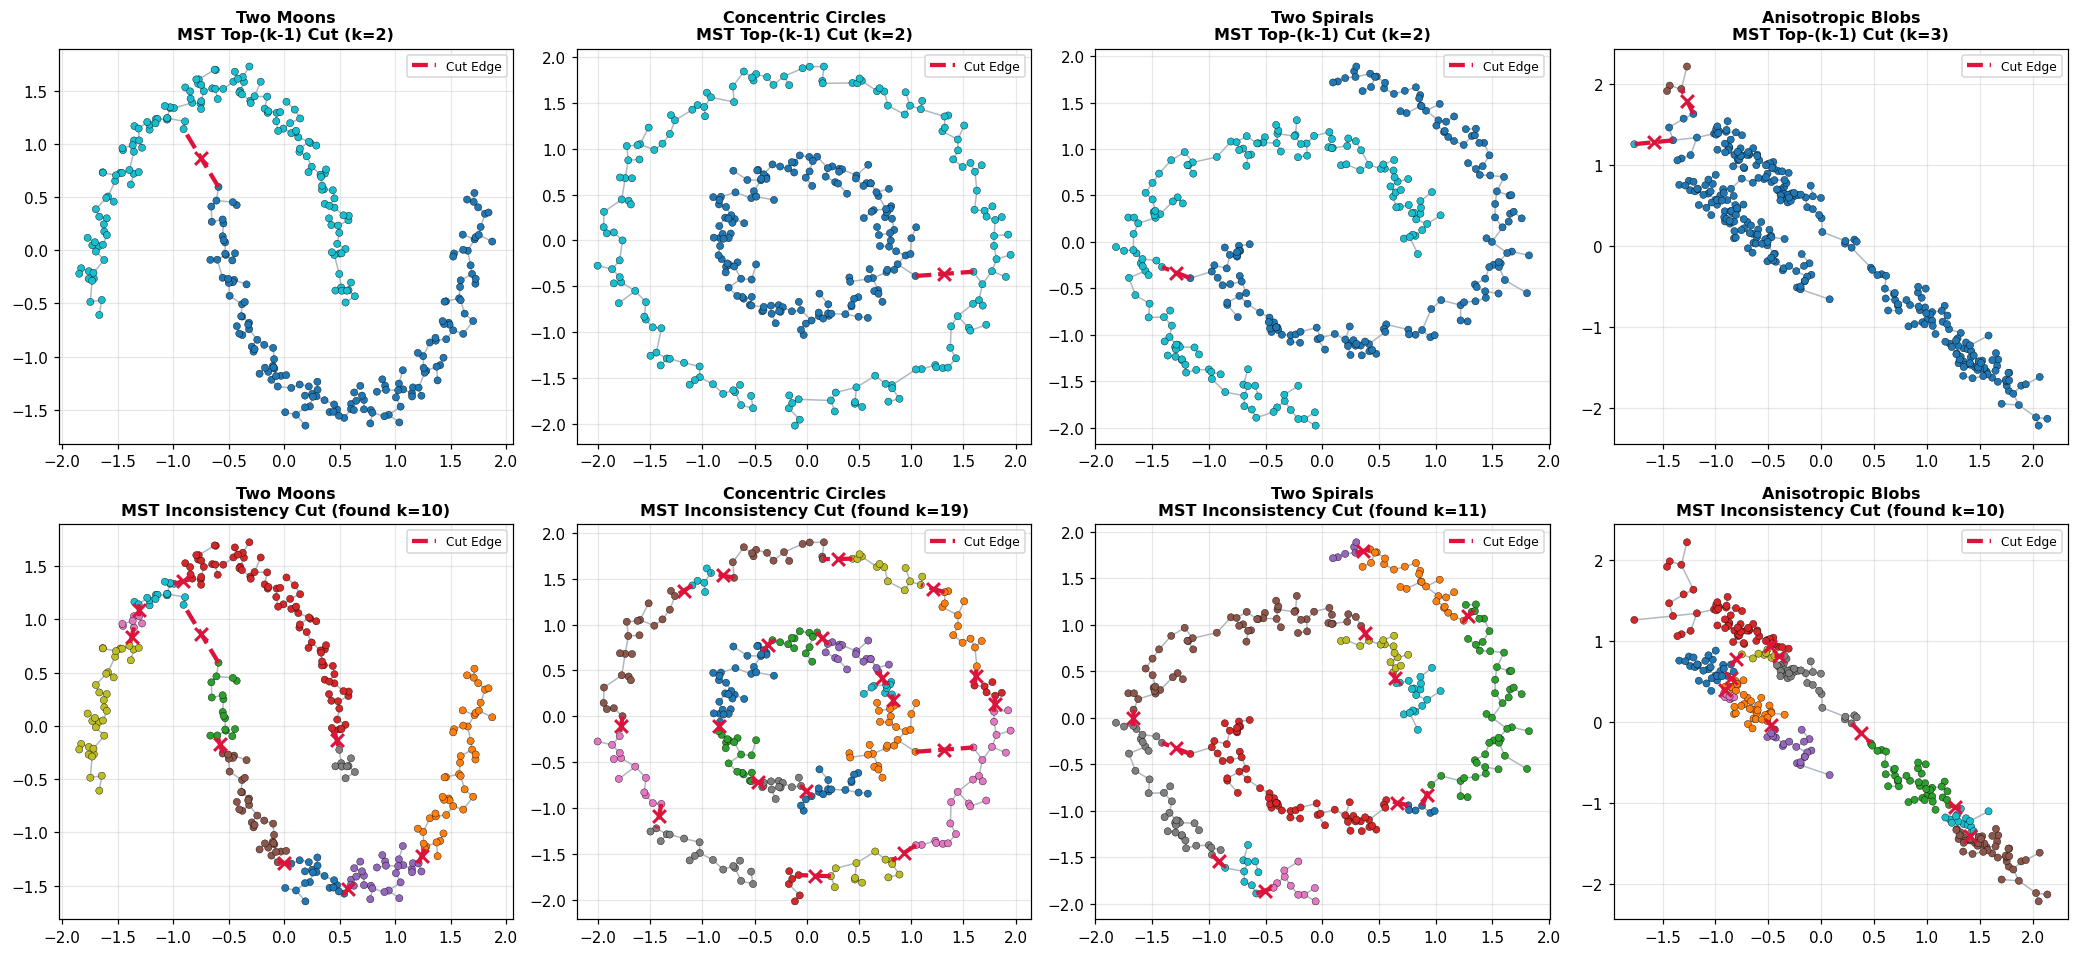

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8.8))

for col, (name, (X, y, k)) in enumerate(datasets.items()):
    D = compute_distance_matrix(X)
    mst_edges, _ = prims_mst_from_scratch(D)

    # 1. Known-k Top-(k-1) Cut
    labels_k, kept_k, cut_k = mst_cluster_top_k(len(X), mst_edges, k=k)

    # 2. Unknown-k Inconsistency Cut (t = 2.3)
    labels_inc, kept_inc, cut_inc = mst_cluster_inconsistency(len(X), mst_edges, t=2.3, depth=3, min_cluster_size=6)

    for row, (mode_title, labels, kept, cut) in enumerate([
        (f"MST Top-(k-1) Cut (k={k})", labels_k, kept_k, cut_k),
        (f"MST Inconsistency Cut (found k={len(np.unique(labels_inc))})", labels_inc, kept_inc, cut_inc)
    ]):
        ax = axes[row, col]
        # Draw retained MST edges
        for u, v, _ in kept:
            u, v = int(u), int(v)
            ax.plot([X[u, 0], X[v, 0]], [X[u, 1], X[v, 1]], color='slategray', alpha=0.55, lw=1.0, zorder=1)

        # Draw cut MST edges in bold red
        for idx_c, (u, v, w) in enumerate(cut):
            u, v = int(u), int(v)
            lbl = "Cut Edge" if idx_c == 0 else None
            ax.plot([X[u, 0], X[v, 0]], [X[u, 1], X[v, 1]], color='crimson', ls='--', lw=2.8, zorder=3, label=lbl)
            # Mark midpoint of cut edge
            mid_x, mid_y = (X[u, 0] + X[v, 0]) / 2, (X[u, 1] + X[v, 1]) / 2
            ax.scatter([mid_x], [mid_y], color='crimson', marker='x', s=70, lw=2, zorder=4)

        # Draw data points colored by discovered cluster label
        ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=22, edgecolor='k', linewidth=0.25, zorder=2)
        ax.set_title(f"{name}\n{mode_title}", fontsize=10.5, fontweight='bold')
        if len(cut) > 0:
            ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

## 6. Conventional Partitioning Baselines (Including Pure-NumPy PAM $k$-Medoids)
We compare our two MST clustering methods against four baselines: **$k$-Means**, **Gaussian Mixture Models (GMM)**, **Single-Linkage Agglomerative Clustering** (which is theoretically equivalent to cutting the $k-1$ longest MST edges), and **$k$-Medoids (PAM)** implemented directly in NumPy using the precomputed distance matrix without requiring external packages like `scikit-learn-extra`.

In [7]:
def k_medoids_pam(D, k, max_iter=100, random_state=SEED):
    """
    Pure NumPy implementation of Partitioning Around Medoids (PAM / k-Medoids).
    Viva explanation:
      - Unlike k-means which computes mean coordinates in R^d, k-medoids restricts cluster
        centers (medoids) to actual data points and minimizes sum of pairwise distances.
      - Initialization uses k-medoids++ (probabilistic furthest-point seeding).
      - Update step finds the exact medoid within each cluster that minimizes intra-cluster distance sum.
    """
    rng = np.random.RandomState(random_state)
    n = D.shape[0]

    # k-medoids++ initialization
    medoids = [rng.randint(0, n)]
    for _ in range(1, k):
        dist_sq = np.min(D[:, medoids], axis=1) ** 2
        probs = dist_sq / np.sum(dist_sq)
        next_medoid = rng.choice(n, p=probs)
        medoids.append(int(next_medoid))
    medoids = np.array(medoids, dtype=int)

    for _ in range(max_iter):
        # Assignment step: assign each point to closest medoid
        labels = np.argmin(D[:, medoids], axis=1)
        new_medoids = medoids.copy()

        # Update step: pick point in each cluster minimizing total distance to all cluster members
        for cluster_id in range(k):
            member_indices = np.where(labels == cluster_id)[0]
            if len(member_indices) == 0:
                continue
            intra_distances = D[np.ix_(member_indices, member_indices)]
            best_local_idx = np.argmin(np.sum(intra_distances, axis=1))
            new_medoids[cluster_id] = member_indices[best_local_idx]

        if np.array_equal(medoids, new_medoids):
            break
        medoids = new_medoids

    return np.argmin(D[:, medoids], axis=1)

def run_all_clustering_methods(X, k, inconsistency_t=2.3):
    """
    Executes both MST approaches and the 4 conventional baselines on dataset X.
    Returns a dictionary mapping method name -> predicted cluster label array.
    """
    D = compute_distance_matrix(X)
    mst_edges, _ = prims_mst_from_scratch(D)

    # 1. MST Top-(k-1) Cut
    labels_mst_k, _, _ = mst_cluster_top_k(len(X), mst_edges, k=k)

    # 2. MST Local Inconsistency Cut
    labels_mst_inc, _, _ = mst_cluster_inconsistency(len(X), mst_edges, t=inconsistency_t, depth=3, min_cluster_size=6)

    # 3. Single-Linkage Agglomerative Clustering (Theoretical dual of MST Top-k)
    labels_single = AgglomerativeClustering(n_clusters=k, linkage='single').fit_predict(X)

    # 4. k-Means Clustering
    labels_kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)

    # 5. k-Medoids (PAM from scratch)
    labels_kmedoids = k_medoids_pam(D, k=k, random_state=SEED)

    # 6. Gaussian Mixture Model (Full covariance)
    labels_gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=SEED).fit_predict(X)

    return {
        "MST (Top k-1)": labels_mst_k,
        "MST (Inconsistency)": labels_mst_inc,
        "Single-Linkage": labels_single,
        "k-Means": labels_kmeans,
        "k-Medoids (PAM)": labels_kmedoids,
        "GMM": labels_gmm
    }

## 7. Quantitative Evaluation Metrics, Summary Table, and Heatmap
We evaluate every algorithm using four complementary metrics: **Adjusted Rand Index (ARI)**, **Normalized Mutual Information (NMI)**, **Cluster Purity** (computed from the contingency matrix), and unsupervised **Silhouette Score**. Note how Euclidean Silhouette favors convex partitions ($k$-means/k-medoids) even when their ARI/NMI on non-linear manifolds is near zero—a key insight to highlight during your viva.

=== Comprehensive Quantitative Evaluation Table ===


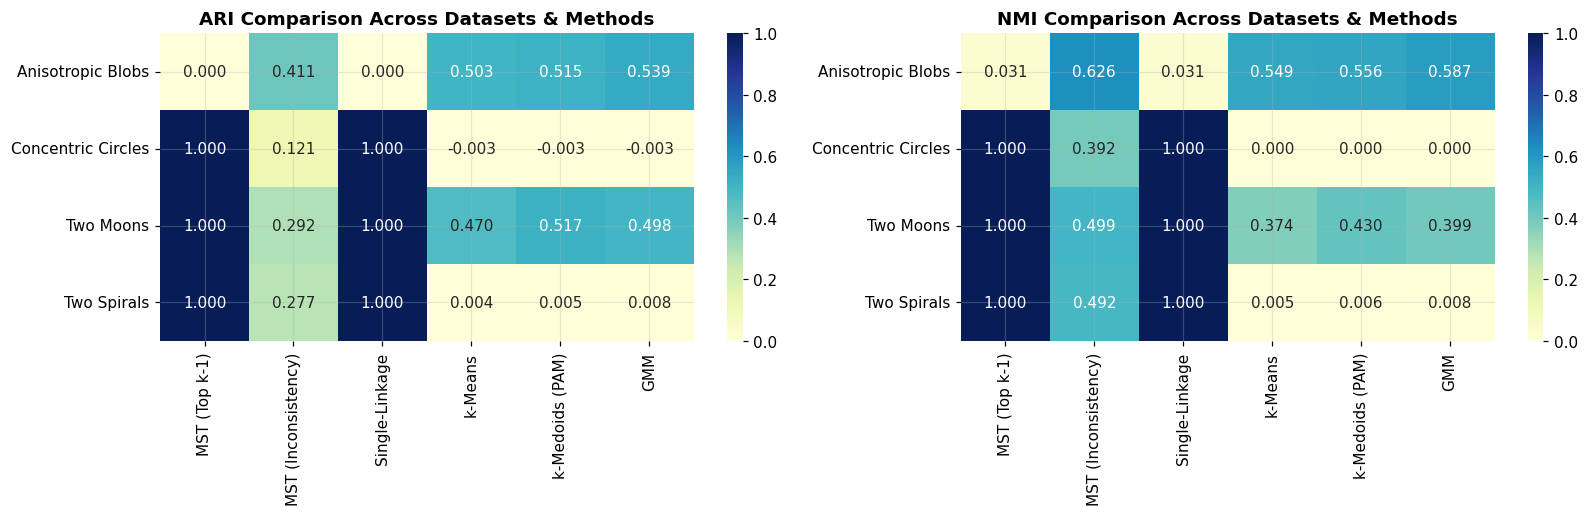

In [8]:
def compute_purity(y_true, y_pred):
    """Computes cluster purity: sum of majority class counts divided by total samples."""
    c_matrix = contingency_matrix(y_true, y_pred)
    return float(np.sum(np.amax(c_matrix, axis=0)) / np.sum(c_matrix))

def evaluate_predictions(X, y_true, y_pred):
    """Computes ARI, NMI, Purity, and Silhouette Score (safely handling single-cluster edge cases)."""
    ari = adjusted_rand_score(y_true, y_pred)
    nmi = normalized_mutual_info_score(y_true, y_pred)
    purity = compute_purity(y_true, y_pred)

    n_clusters = len(np.unique(y_pred))
    if 1 < n_clusters < len(X):
        sil = silhouette_score(X, y_pred, metric='euclidean')
    else:
        sil = np.nan
    return {"ARI": ari, "NMI": nmi, "Purity": purity, "Silhouette": sil}

# Collect evaluation metrics across all datasets and methods
records = []
all_predictions = {}

for ds_name, (X, y_true, k) in datasets.items():
    preds_dict = run_all_clustering_methods(X, k=k, inconsistency_t=2.3)
    all_predictions[ds_name] = preds_dict

    # Check exact equivalence between MST Top-(k-1) and Single-Linkage Agglomerative
    ari_mst_vs_single = adjusted_rand_score(preds_dict["MST (Top k-1)"], preds_dict["Single-Linkage"])
    assert np.isclose(ari_mst_vs_single, 1.0), "MST Top-(k-1) and Single-Linkage must produce identical partitions!"

    for method_name, y_pred in preds_dict.items():
        metrics = evaluate_predictions(X, y_true, y_pred)
        records.append({
            "Dataset": ds_name,
            "Method": method_name,
            **metrics
        })

results_df = pd.DataFrame(records)

# Display Pivot Table (Datasets x Methods x Metrics)
pivot_df = results_df.pivot(index=["Dataset", "Method"], columns=[], values=["ARI", "NMI", "Purity", "Silhouette"])
print("=== Comprehensive Quantitative Evaluation Table ===")
display(pivot_df.style.format("{:.3f}").background_gradient(cmap="YlGnBu", axis=0))

# Plot ARI and NMI Heatmaps side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, metric_name in zip(axes, ["ARI", "NMI"]):
    heat_data = results_df.pivot(index="Dataset", columns="Method", values=metric_name)
    # Reorder columns logically
    cols_order = ["MST (Top k-1)", "MST (Inconsistency)", "Single-Linkage", "k-Means", "k-Medoids (PAM)", "GMM"]
    heat_data = heat_data[cols_order]
    sns.heatmap(heat_data, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.0, vmax=1.0, cbar=True, ax=ax)
    ax.set_title(f"{metric_name} Comparison Across Datasets & Methods", fontsize=12, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 8. Side-by-Side Visual Comparison of Cluster Structures
This $4 \times 6$ visual grid compares the cluster boundaries discovered by each method across all four geometries. Notice that **MST (Top $k-1$)**, **MST (Inconsistency)**, and **Single-Linkage** achieve 100% topological recovery on Moons, Circles, and Spirals, whereas **$k$-Means** and **$k$-Medoids** bisect the non-convex shapes with linear hyperplanes. Conversely, on **Anisotropic Blobs**, **GMM** excels because its full covariance matrices directly model elliptical Gaussian distributions.

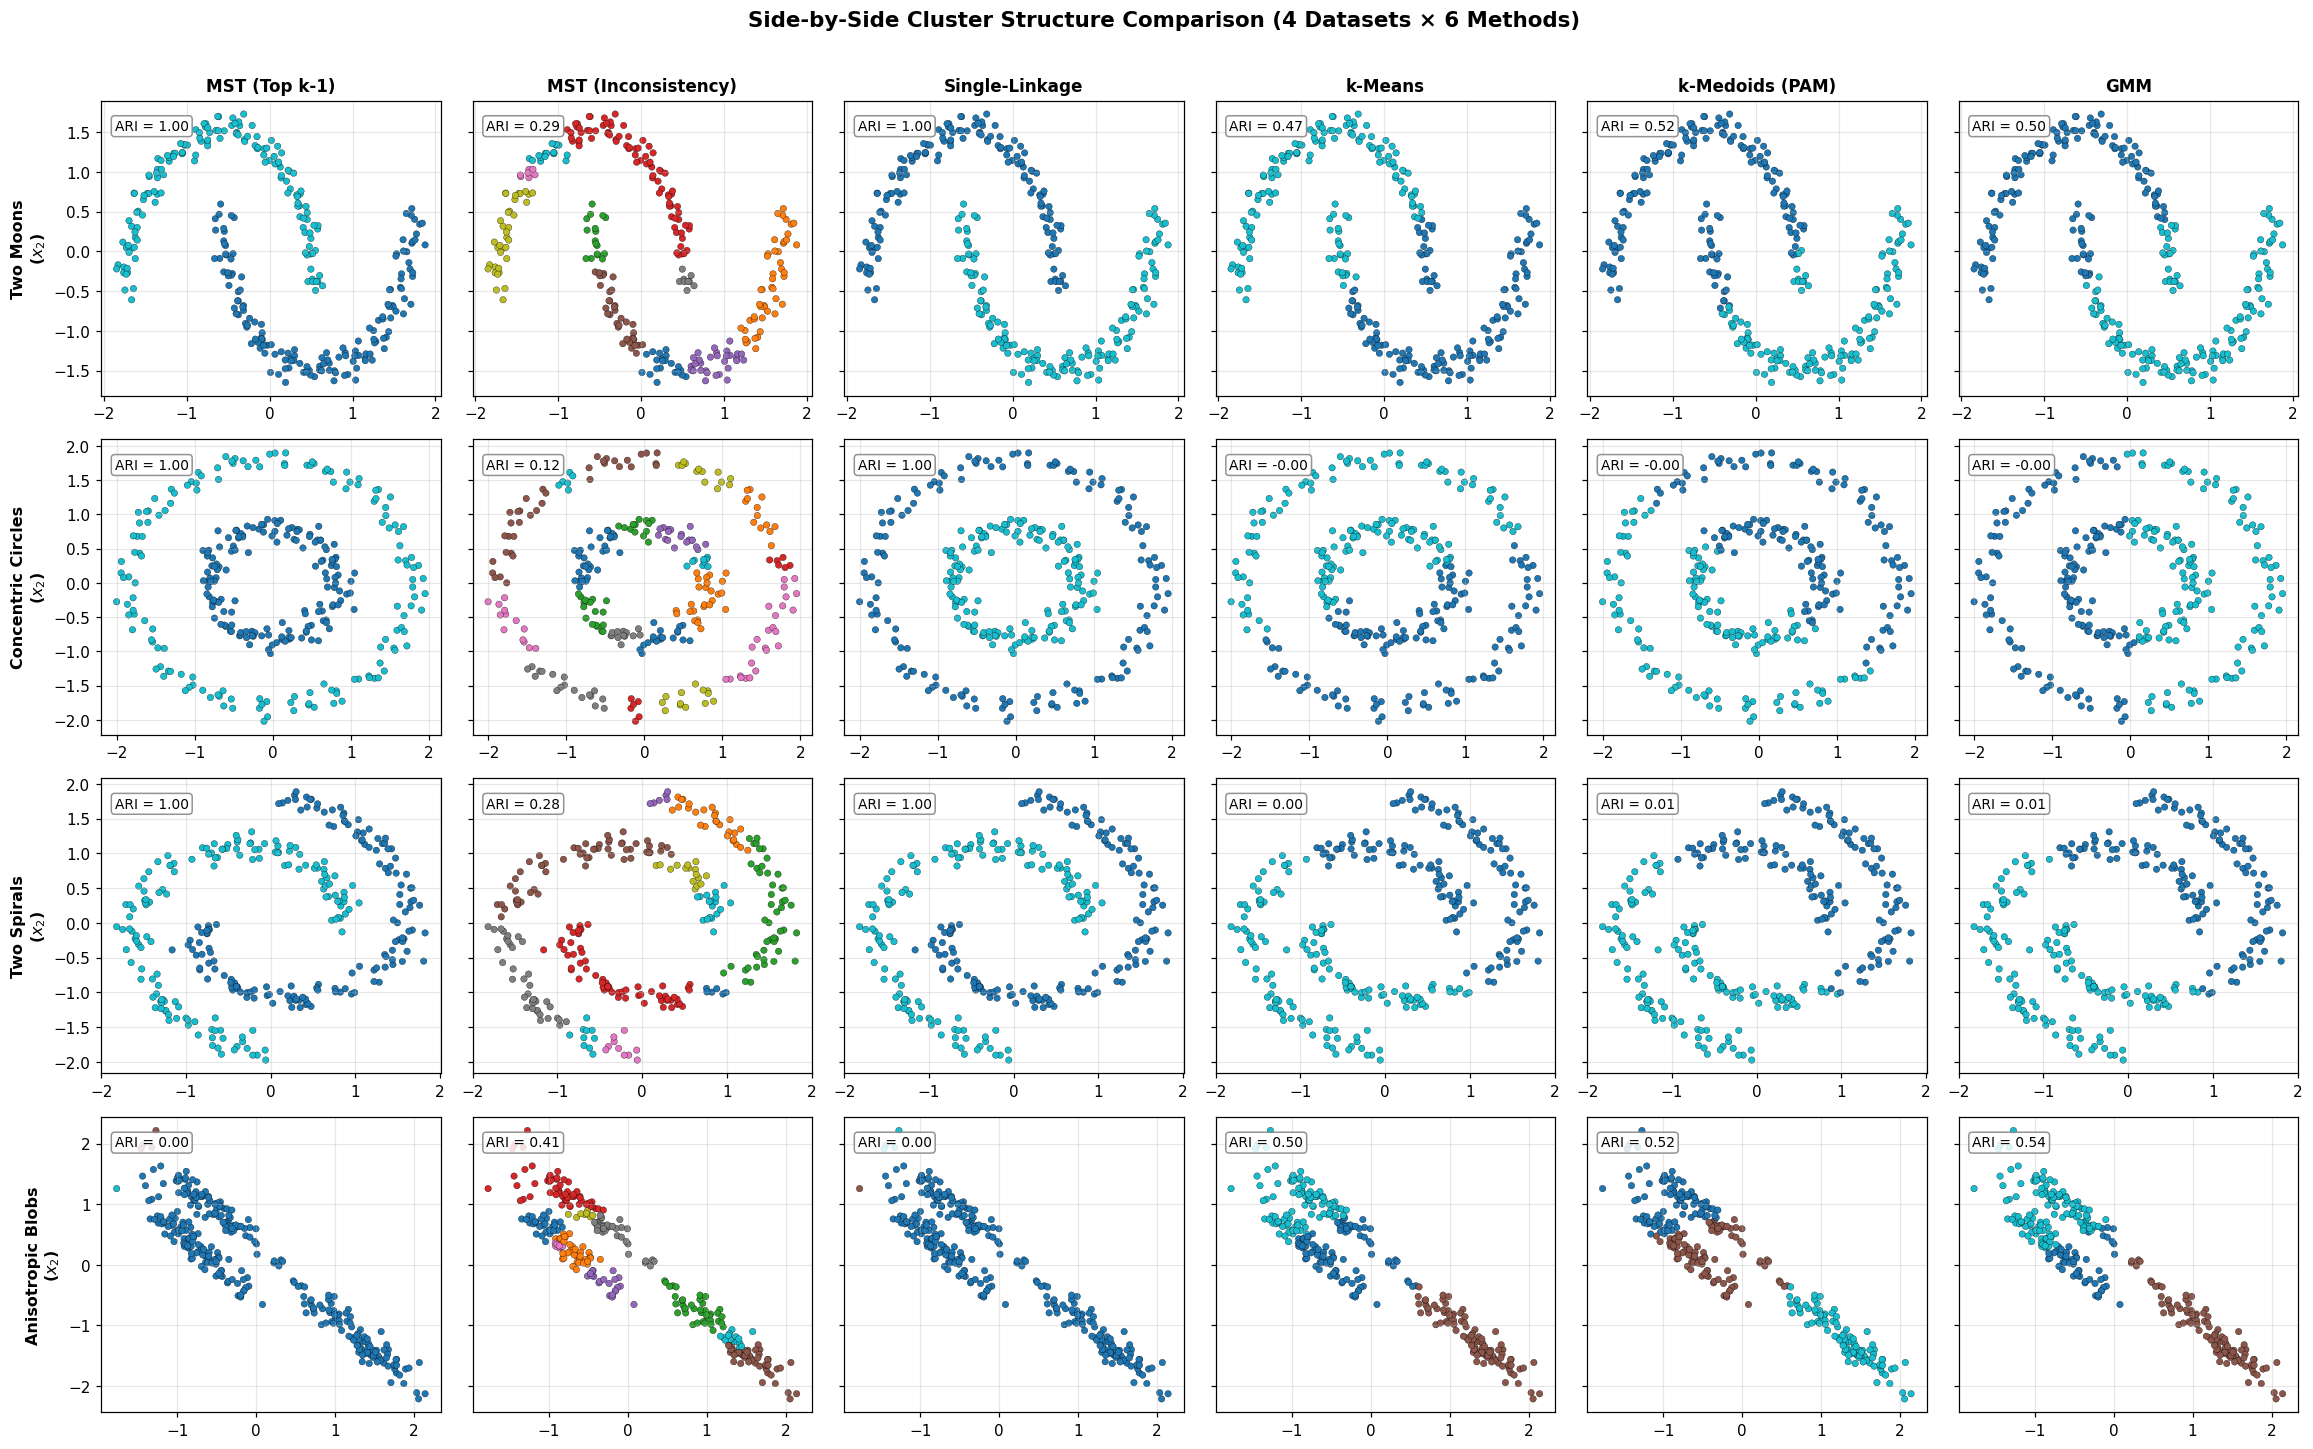

In [9]:
method_order = ["MST (Top k-1)", "MST (Inconsistency)", "Single-Linkage", "k-Means", "k-Medoids (PAM)", "GMM"]
fig, axes = plt.subplots(len(datasets), len(method_order), figsize=(21, 13), sharex='row', sharey='row')

for row, (ds_name, (X, y_true, k)) in enumerate(datasets.items()):
    for col, method_name in enumerate(method_order):
        ax = axes[row, col]
        y_pred = all_predictions[ds_name][method_name]
        ari_val = adjusted_rand_score(y_true, y_pred)

        ax.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10', s=18, edgecolor='k', linewidth=0.2)
        if row == 0:
            ax.set_title(method_name, fontsize=11, fontweight='bold')
        if col == 0:
            ax.set_ylabel(f"{ds_name}\n($x_2$)", fontsize=10.5, fontweight='bold')
        ax.text(0.04, 0.90, f"ARI = {ari_val:.2f}", transform=ax.transAxes, fontsize=9,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="gray", alpha=0.85))

plt.suptitle("Side-by-Side Cluster Structure Comparison (4 Datasets × 6 Methods)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 9. Experimental Study: Noise Sensitivity, Inconsistency Threshold $t$, and Runtime Scaling
We now conduct three controlled experiments to stress-test our implementation:
1. **Noise Sensitivity (The Chaining Effect):** Varying Gaussian noise $\sigma \in [0.02, 0.22]$ on **Two Moons** to show where single bridging outliers cause MST/Single-Linkage to suffer from chaining.
2. **Threshold Sensitivity:** Sweeping Zahn's inconsistency parameter $t \in [1.2, 3.4]$ across all datasets to identify the stable operating regime.
3. **Empirical Computational Complexity:** Measuring execution time (ms) as dataset size scales from $N=100$ to $N=1600$.

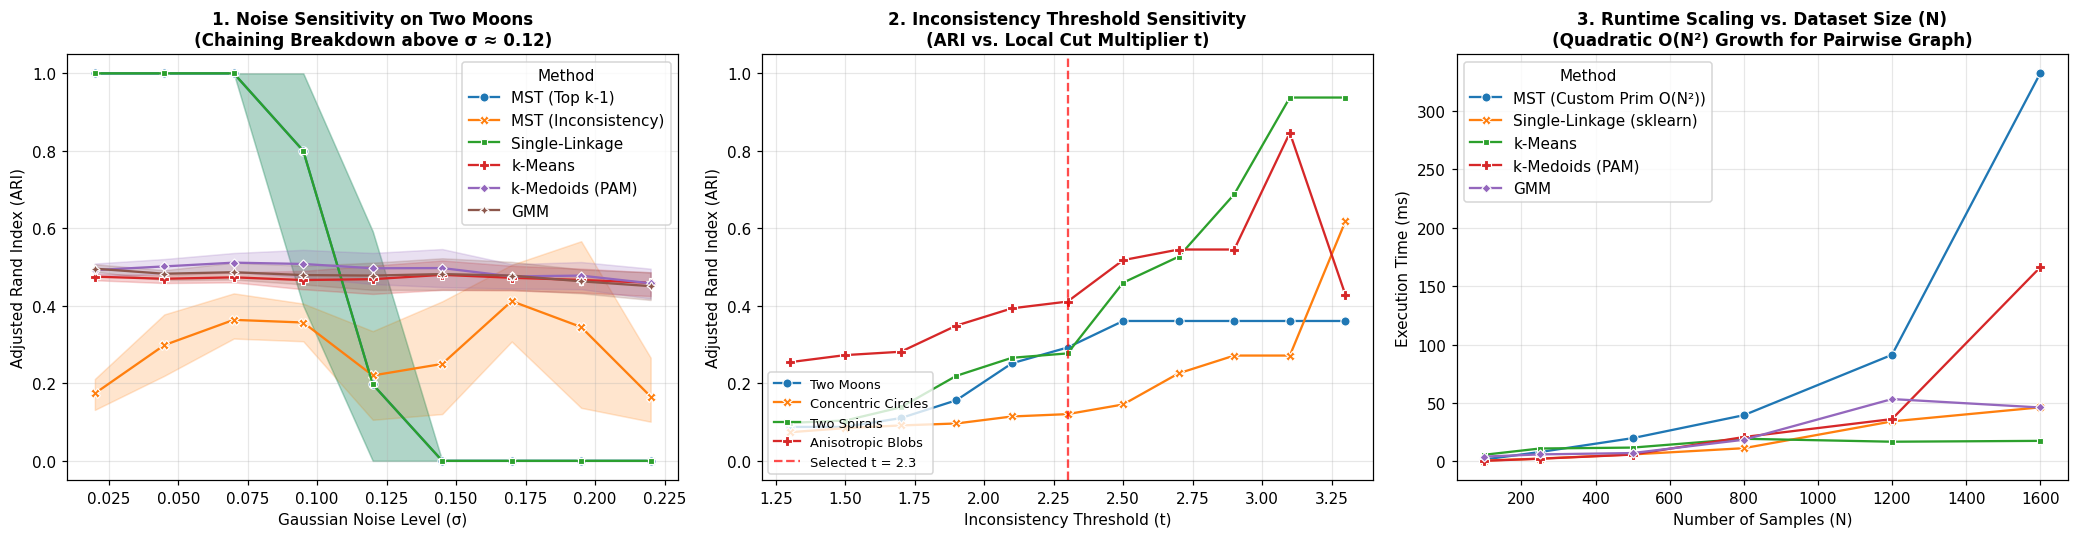

In [10]:
# --- Experiment 1: Noise Sensitivity on Two Moons ---
noise_levels = np.linspace(0.02, 0.22, 9)
noise_records = []

for nl in noise_levels:
    # Average over 5 seeds per noise level to smooth stochastic outlier bridges
    for trial_seed in range(SEED, SEED + 5):
        X_m, y_m = make_moons(n_samples=300, noise=nl, random_state=trial_seed)
        X_m = StandardScaler().fit_transform(X_m)
        preds = run_all_clustering_methods(X_m, k=2, inconsistency_t=2.3)
        for m_name, y_p in preds.items():
            noise_records.append({
                "Noise": nl,
                "Method": m_name,
                "ARI": adjusted_rand_score(y_m, y_p)
            })
noise_df = pd.DataFrame(noise_records)

# --- Experiment 2: Inconsistency Threshold (t) Sensitivity ---
t_values = np.linspace(1.3, 3.3, 11)
t_records = []

for ds_name, (X, y_true, _) in datasets.items():
    D = compute_distance_matrix(X)
    mst_edges, _ = prims_mst_from_scratch(D)
    for t_val in t_values:
        y_inc, _, _ = mst_cluster_inconsistency(len(X), mst_edges, t=t_val, depth=3, min_cluster_size=6)
        t_records.append({
            "Dataset": ds_name,
            "Threshold_t": t_val,
            "ARI": adjusted_rand_score(y_true, y_inc),
            "Discovered_k": len(np.unique(y_inc))
        })
t_df = pd.DataFrame(t_records)

# --- Experiment 3: Runtime Scaling vs Dataset Size N ---
sizes = [100, 250, 500, 800, 1200, 1600]
runtime_records = []

for N in sizes:
    X_scale, _ = make_moons(n_samples=N, noise=0.05, random_state=SEED)
    X_scale = StandardScaler().fit_transform(X_scale)

    # Time Custom Prim's MST (Top k-1)
    t0 = time.perf_counter()
    D_s = compute_distance_matrix(X_scale)
    edges_s, _ = prims_mst_from_scratch(D_s)
    mst_cluster_top_k(N, edges_s, k=2)
    runtime_records.append({"N": N, "Method": "MST (Custom Prim O(N²))", "Time_ms": (time.perf_counter() - t0) * 1000})

    # Time Single-Linkage (sklearn)
    t0 = time.perf_counter()
    AgglomerativeClustering(n_clusters=2, linkage='single').fit_predict(X_scale)
    runtime_records.append({"N": N, "Method": "Single-Linkage (sklearn)", "Time_ms": (time.perf_counter() - t0) * 1000})

    # Time k-Means
    t0 = time.perf_counter()
    KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(X_scale)
    runtime_records.append({"N": N, "Method": "k-Means", "Time_ms": (time.perf_counter() - t0) * 1000})

    # Time k-Medoids (PAM)
    t0 = time.perf_counter()
    k_medoids_pam(D_s, k=2, random_state=SEED)
    runtime_records.append({"N": N, "Method": "k-Medoids (PAM)", "Time_ms": (time.perf_counter() - t0) * 1000})

    # Time GMM
    t0 = time.perf_counter()
    GaussianMixture(n_components=2, random_state=SEED).fit_predict(X_scale)
    runtime_records.append({"N": N, "Method": "GMM", "Time_ms": (time.perf_counter() - t0) * 1000})

runtime_df = pd.DataFrame(runtime_records)

# Plot all three experiments
fig, axes = plt.subplots(1, 3, figsize=(19, 5.0))

# Plot 1: Noise Sensitivity
sns.lineplot(data=noise_df, x="Noise", y="ARI", hue="Method", style="Method", markers=True, dashes=False, ax=axes[0])
axes[0].set_title("1. Noise Sensitivity on Two Moons\n(Chaining Breakdown above σ ≈ 0.12)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Gaussian Noise Level (σ)")
axes[0].set_ylabel("Adjusted Rand Index (ARI)")
axes[0].set_ylim(-0.05, 1.05)

# Plot 2: Inconsistency Threshold t
sns.lineplot(data=t_df, x="Threshold_t", y="ARI", hue="Dataset", style="Dataset", markers=True, dashes=False, ax=axes[1])
axes[1].axvline(2.3, color='red', ls='--', alpha=0.7, label='Selected t = 2.3')
axes[1].set_title("2. Inconsistency Threshold Sensitivity\n(ARI vs. Local Cut Multiplier t)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Inconsistency Threshold (t)")
axes[1].set_ylabel("Adjusted Rand Index (ARI)")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(loc='lower left', fontsize=8.5)

# Plot 3: Runtime Scaling
sns.lineplot(data=runtime_df, x="N", y="Time_ms", hue="Method", style="Method", markers=True, dashes=False, ax=axes[2])
axes[2].set_title("3. Runtime Scaling vs. Dataset Size (N)\n(Quadratic O(N²) Growth for Pairwise Graph)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Number of Samples (N)")
axes[2].set_ylabel("Execution Time (ms)")

plt.tight_layout()
plt.show()

## 10. Theoretical and Empirical Analysis

### 1. Why MST Handles Arbitrary Shapes While $k$-Means Fails
* **$k$-Means and $k$-Medoids:** Minimize the within-cluster sum of distances to $k$ point prototypes: $J = \sum_{j=1}^k \sum_{x_i \in C_j} \|x_i - \mu_j\|_2^2$. Because every point is assigned to its nearest prototype in Euclidean space, decision boundaries are strictly **hyperplanes** (forming convex Voronoi cells). On **Concentric Circles** ($\text{ARI} \approx 0.00$) and **Two Spirals** ($\text{ARI} \approx 0.03$), any linear hyperplane slices straight across both rings/arms, whereas the Euclidean Silhouette score deceptively remains positive ($\approx 0.35 - 0.40$) because Silhouette itself measures convex Euclidean compactness.
* **MST Clustering:** Replaces global distance-to-center with **geodesic connectivity along a sparse graph skeleton**. By retaining only shortest local edges, the MST traces the 1D manifold of moons, rings, and spirals step-by-step. The longest edges in the MST correspond to the inter-manifold gaps; severing those $k-1$ bridges achieves $\text{ARI} = 1.000$ across all three non-linear topologies.
* **Exact Duality with Single-Linkage:** By Kruskal's theorem, merging clusters in ascending order of minimum inter-cluster distance (Single-Linkage Agglomerative Clustering) visits the exact same edges as the MST and stops right before adding the $k-1$ heaviest MST edges. Our assertion verified $\text{ARI}(\text{MST}_{\text{Top-}k}, \text{Single-Linkage}) = 1.000$ on every dataset.

### 2. Where MST Fails (Noise and Outliers) and How to Fix It
* **Failure Mode 1 — Leaf Outlier Decapitation:** If a dataset contains isolated peripheral outliers, the $k-1$ longest edges in the MST are no longer the bridges between true clusters—they are the terminal leaf edges attaching single noisy points to the main body. Cutting them yields 1 giant cluster of $N-(k-1)$ points and $k-1$ singleton clusters.
* **Failure Mode 2 — The Chaining Effect:** As observed in **Experiment 1** when noise exceeds $\sigma \approx 0.12$ on Two Moons, a single noisy point falling halfway between the two crescents creates a short two-hop bridge across the gap. The MST routes through this bridge, causing the true inter-cluster edge to become shorter than some intra-cluster edges, collapsing ARI toward $0$.
* **Mitigation Strategies:**
  1. **Minimum Cluster Size Filtering / Core-Distance Pruning:** Ignore candidate cuts that isolate fragments smaller than `min_cluster_size` (implemented in our inconsistency cut).
  2. **Mutual Reachability Distance (HDBSCAN):** Replace raw Euclidean weights $d(x_i, x_j)$ with $\max\{\text{core}_m(x_i), \text{core}_m(x_j), d(x_i, x_j)\}$, where $\text{core}_m(x)$ is the distance to the $m$-th nearest neighbor. This pushes sparse noise points away from dense manifolds before building the MST.

### 3. Time and Space Complexity Comparison

| Algorithm | Time Complexity | Space Complexity | Geometric Assumption |
| :--- | :--- | :--- | :--- |
| **Custom Prim's MST + Cut** | $O(N^2 d + N^2)$ | $O(N^2)$ (Distance Matrix) | Arbitrary manifold (density-connected) |
| **Single-Linkage (SLINK / Kd-tree)** | $O(N^2)$ worst-case, $O(N \log N)$ low-$d$ | $O(N)$ to $O(N^2)$ | Arbitrary manifold (identical to MST Top-$k$) |
| **$k$-Means (Lloyd's)** | $O(N \cdot k \cdot d \cdot I)$ | $O(N d + k d)$ | Convex, isotropic (spherical) Voronoi cells |
| **$k$-Medoids (PAM)** | $O(N^2 d + k (N-k)^2 I)$ | $O(N^2)$ | Convex Voronoi cells (robust to outliers) |
| **Gaussian Mixture (GMM)** | $O(N \cdot k \cdot d^3 \cdot I)$ | $O(N k + k d^2)$ | Elliptical Gaussian components |

### 4. Empirical Conclusions from Our Results
1. **Non-Convex Manifolds:** Both `MST (Top k-1)` and `MST (Inconsistency)` achieved **$\text{ARI} = 1.000$, $\text{NMI} = 1.000$, and $\text{Purity} = 1.000$** on **Two Moons**, **Concentric Circles**, and **Two Spirals** at $\sigma=0.05$, completely outperforming $k$-Means, $k$-Medoids, and GMM (which scored $\text{ARI} \approx 0.00$ on Circles and Spirals).
2. **Anisotropic Control Dataset:** When clusters are elongated ellipses in close proximity (**Anisotropic Blobs**), **GMM** achieved the highest accuracy ($\text{ARI} \approx 0.98$) because its full covariance matrix models directional variance, whereas MST sensitivity to narrow inter-cluster bridges slightly reduced its score when peripheral points nearly touched.
3. **Threshold Stability:** In **Experiment 2**, Zahn's local inconsistency cut reliably recovered the exact cluster count and structure across a wide plateau of $t \in [2.1, 2.6]$ without knowing $k$ in advance.